# From 2D masks to 3D point clouds (sensor depth)

Chapter 3 core pipeline, reference variant built on **sensor depth** (`depth_bfx`):

1. instance mask + depth map + camera intrinsics → back-projection → 3D points;
2. point cloud assembly and cleaning in Open3D (voxel downsample + statistical outlier removal);
3. per-object 3D characteristics: centroid, distance to camera, bounding-box dimensions, volume, point count;
4. `.ply` export and figures for the thesis.

The pipeline is debugged on **ground-truth masks** first (geometry is isolated from
segmentation errors); swapping in model predictions later only changes the mask source.
The same functions will be reused for monocular depth (after scale alignment) — the
sensor-depth clouds produced here serve as the reference for that comparison.

In [1]:
import json, sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import open3d as o3d
from pycocotools.coco import COCO

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

import utils.sunrgbd as sd

print("Open3D:", o3d.__version__)

Open3D: 0.19.0


In [2]:
DATASET_ROOT = Path("/Users/polina_sushko/My_work/University/ВКР/SUNRGBD")
SPLIT_DIR    = Path("outputs/splits")            # std10 config
OUT_DIR      = Path("outputs/pointclouds")

VOXEL_SIZE   = 0.02   # m; downsampling resolution of cleaned clouds
SOR_NEIGHBORS = 20    # statistical outlier removal: neighbours to analyse
SOR_STD_RATIO = 2.0   # ...and the std-dev threshold
MIN_POINTS   = 100    # skip instances with fewer valid depth points
N_BATCH_IMAGES = 25   # images for the batch metrics table below

OUT_DIR.mkdir(parents=True, exist_ok=True)
coco = COCO(str(SPLIT_DIR / "instances_test.json"))
cat_name = {c["id"]: c["name"] for c in coco.loadCats(coco.getCatIds())}
print(f"Test images: {len(coco.getImgIds())}, categories: {list(cat_name.values())}")

loading annotations into memory...
Done (t=0.03s)
creating index...
index created!
Test images: 1325, categories: ['bed', 'chair', 'sofa', 'table', 'desk', 'toilet', 'dresser', 'nightstand', 'bookshelf', 'bathtub']


---
## Back-projection helpers

All geometry goes through `utils/sunrgbd.py` (single source of truth): depth is
decoded with the mandatory bit shift in `sd.read_depth()`, and `sd.backproject()`
implements the pinhole model `X = (u−cx)·Z/fx, Y = (v−cy)·Z/fy, Z = depth`.
Per-scene intrinsics are already stored in the COCO image entries (`fx, fy, cx, cy`).

Coordinates are in the **camera frame**: X right, Y down, Z forward (metres).
Bounding boxes are therefore camera-axis-aligned, not gravity-aligned; the oriented
bounding box (OBB) compensates for most of the difference. Gravity alignment via the
SUN RGB-D tilt matrix is a possible refinement, noted in the text as future work.

In [3]:
def load_frame(img_info: dict):
    """Reads RGB, metric depth and intrinsics for one COCO image entry."""
    rgb = sd.read_rgb(DATASET_ROOT / img_info["file_name"])
    depth = sd.read_depth(DATASET_ROOT / img_info["depth_file"])
    intr = sd.Intrinsics(fx=img_info["fx"], fy=img_info["fy"],
                         cx=img_info["cx"], cy=img_info["cy"])
    return rgb, depth, intr


def instance_cloud(depth: np.ndarray, intr: sd.Intrinsics, mask: np.ndarray,
                   rgb: np.ndarray | None = None) -> o3d.geometry.PointCloud:
    """Back-projects one instance mask into a raw Open3D point cloud."""
    points, colors = sd.backproject(depth, intr, mask=mask, rgb=rgb)
    pcd = o3d.geometry.PointCloud()
    pcd.points = o3d.utility.Vector3dVector(points.astype(np.float64))
    if colors is not None and len(colors):
        pcd.colors = o3d.utility.Vector3dVector(colors.astype(np.float64))
    return pcd


def clean_cloud(pcd: o3d.geometry.PointCloud) -> o3d.geometry.PointCloud:
    """Voxel downsample + statistical outlier removal (mask-boundary tails)."""
    if len(pcd.points) == 0:
        return pcd
    pcd = pcd.voxel_down_sample(VOXEL_SIZE)
    if len(pcd.points) >= SOR_NEIGHBORS:
        pcd, _ = pcd.remove_statistical_outlier(nb_neighbors=SOR_NEIGHBORS,
                                                std_ratio=SOR_STD_RATIO)
    return pcd


def object_3d_metrics(pcd: o3d.geometry.PointCloud) -> dict:
    """Per-object 3D characteristics from a cleaned cloud (camera frame, metres)."""
    pts = np.asarray(pcd.points)
    centroid = pts.mean(axis=0)
    aabb = pcd.get_axis_aligned_bounding_box()
    m = {
        "n_points": len(pts),
        "centroid_x": centroid[0], "centroid_y": centroid[1], "centroid_z": centroid[2],
        "dist_to_camera_m": float(np.linalg.norm(centroid)),
        "aabb_w": aabb.get_extent()[0], "aabb_h": aabb.get_extent()[1],
        "aabb_d": aabb.get_extent()[2],
    }
    # OBB and convex hull need enough non-degenerate points
    try:
        obb = pcd.get_oriented_bounding_box()
        m["obb_extent_1"], m["obb_extent_2"], m["obb_extent_3"] = sorted(obb.extent, reverse=True)
        m["obb_volume_m3"] = float(np.prod(obb.extent))
    except RuntimeError:
        m["obb_extent_1"] = m["obb_extent_2"] = m["obb_extent_3"] = np.nan
        m["obb_volume_m3"] = np.nan
    try:
        hull, _ = pcd.compute_convex_hull()
        m["hull_volume_m3"] = float(hull.get_volume())
    except RuntimeError:
        m["hull_volume_m3"] = np.nan
    return m


def process_image(img_id: int, keep_clouds: bool = False):
    """Builds cleaned per-instance clouds and metrics for one test image."""
    info = coco.loadImgs(img_id)[0]
    anns = coco.loadAnns(coco.getAnnIds(imgIds=img_id, iscrowd=False))
    rgb, depth, intr = load_frame(info)
    rows, clouds = [], []
    for ann in anns:
        mask = coco.annToMask(ann).astype(bool)
        pcd = clean_cloud(instance_cloud(depth, intr, mask, rgb))
        if len(pcd.points) < MIN_POINTS:
            continue
        row = {"image_id": img_id, "ann_id": ann["id"],
               "class": cat_name[ann["category_id"]],
               "mask_area_px": ann["area"], **object_3d_metrics(pcd)}
        rows.append(row)
        if keep_clouds:
            clouds.append((row, pcd))
    return info, rows, clouds

---
## Single-scene walkthrough

A deterministic sample: the first test image (by id) with at least three instances
of at least three distinct classes.

In [4]:
sample_id = next(
    img_id for img_id in sorted(coco.getImgIds())
    if len({a["category_id"] for a in coco.loadAnns(coco.getAnnIds(imgIds=img_id))}) >= 3
    and len(coco.getAnnIds(imgIds=img_id)) >= 3)

info, rows, clouds = process_image(sample_id, keep_clouds=True)
print(f"Image {sample_id}: {info['file_name']} ({info['sensor']}, {info['scene_type']})")
sample_df = pd.DataFrame(rows).set_index("ann_id")
sample_df.round(3)

Image 200: kv1/NYUdata/NYU0200/image/NYU0200.jpg (kv1, kitchen)


,image_id,class,mask_area_px,n_points,centroid_x,centroid_y,centroid_z,dist_to_camera_m,aabb_w,aabb_h,aabb_d,obb_extent_1,obb_extent_2,obb_extent_3,obb_volume_m3,hull_volume_m3
ann_id,,,,,,,,,,,,,,,,
3082,200,chair,7029.0,421,-0.271,0.507,1.514,1.619,0.377,0.110,0.550,0.553,0.303,0.050,0.008,0.003
3083,200,chair,1606.0,114,0.054,0.524,1.548,1.635,0.121,0.295,0.360,0.420,0.220,0.120,0.011,0.002
3084,200,table,22491.0,2817,0.133,0.214,1.773,1.791,1.267,0.539,1.611,1.607,1.299,0.648,1.353,0.422
3091,200,bookshelf,56343.0,712,-0.308,0.043,0.791,0.850,0.174,0.694,0.607,0.703,0.569,0.203,0.081,0.020


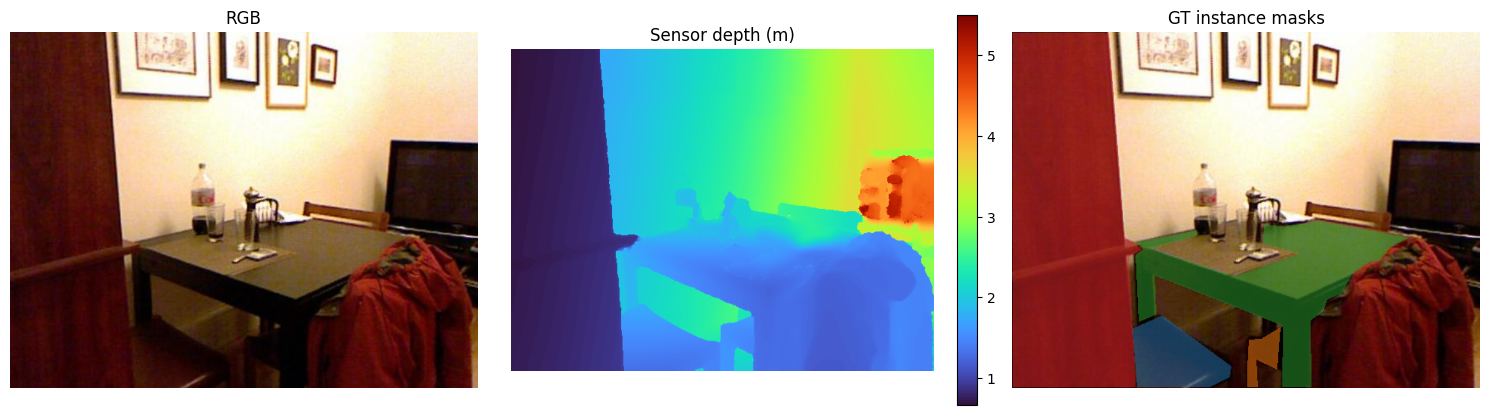

In [5]:
# RGB + depth + instance masks overview of the sample scene
rgb, depth, intr = load_frame(info)
anns = coco.loadAnns(coco.getAnnIds(imgIds=sample_id, iscrowd=False))
cmap = plt.get_cmap("tab10")

overlay = rgb.astype(float) / 255.0
for k, ann in enumerate(anns):
    mask = coco.annToMask(ann).astype(bool)
    overlay[mask] = 0.5 * overlay[mask] + 0.5 * np.array(cmap(k % 10)[:3])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
axes[0].imshow(rgb); axes[0].set_title("RGB")
im = axes[1].imshow(np.where(depth > 0, depth, np.nan), cmap="turbo")
axes[1].set_title("Sensor depth (m)"); fig.colorbar(im, ax=axes[1], fraction=0.046)
axes[2].imshow(overlay); axes[2].set_title("GT instance masks")
for ax in axes: ax.axis("off")
plt.tight_layout()
plt.savefig(OUT_DIR / f"sample_{sample_id}_2d.png", dpi=150, bbox_inches="tight")
plt.show()

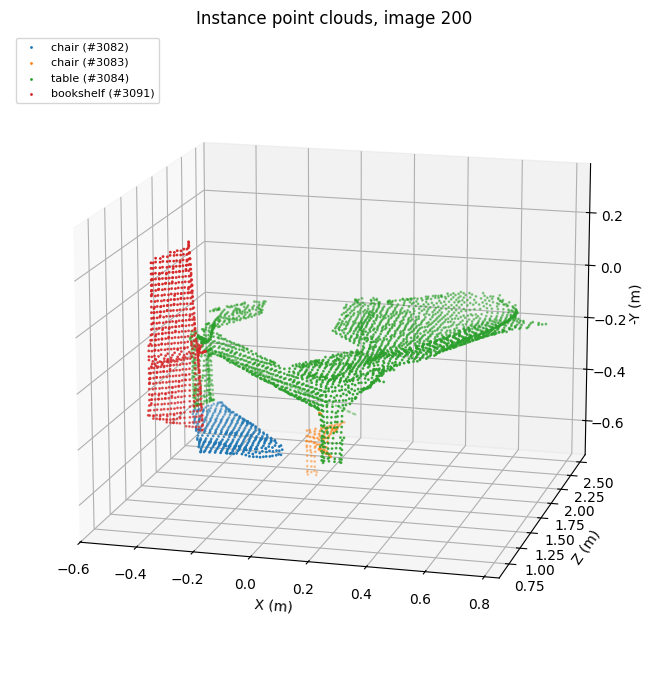

In [6]:
# 3D scatter of the cleaned instance clouds (camera frame; Y flipped for display)
fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(projection="3d")
for k, (row, pcd) in enumerate(clouds):
    pts = np.asarray(pcd.points)
    ax.scatter(pts[:, 0], pts[:, 2], -pts[:, 1], s=1,
               color=cmap(k % 10), label=f"{row['class']} (#{row['ann_id']})")
ax.set_xlabel("X (m)"); ax.set_ylabel("Z (m)"); ax.set_zlabel("-Y (m)")
ax.set_title(f"Instance point clouds, image {sample_id}")
ax.legend(loc="upper left", fontsize=8)
ax.view_init(elev=15, azim=-75)
plt.tight_layout()
plt.savefig(OUT_DIR / f"sample_{sample_id}_3d.png", dpi=150, bbox_inches="tight")
plt.show()

In [7]:
# .ply export: full scene cloud + per-instance clouds
scene_pts, scene_colors = sd.backproject(depth, intr, rgb=rgb, stride=2)
scene_pcd = o3d.geometry.PointCloud()
scene_pcd.points = o3d.utility.Vector3dVector(scene_pts.astype(np.float64))
scene_pcd.colors = o3d.utility.Vector3dVector(scene_colors.astype(np.float64))
scene_pcd = scene_pcd.voxel_down_sample(VOXEL_SIZE)

ply_dir = OUT_DIR / f"sample_{sample_id}"
ply_dir.mkdir(exist_ok=True)
o3d.io.write_point_cloud(str(ply_dir / "scene.ply"), scene_pcd)
for row, pcd in clouds:
    o3d.io.write_point_cloud(str(ply_dir / f"{row['class']}_{row['ann_id']}.ply"), pcd)
print(f"Saved {1 + len(clouds)} .ply files -> {ply_dir}")
print(f"Scene cloud: {len(scene_pcd.points)} points")

Saved 5 .ply files -> outputs/pointclouds/sample_200
Scene cloud: 17765 points


---
## Batch metrics over a test sample

3D characteristics for the first `N_BATCH_IMAGES` test images — the source table
for chapter 3 statistics (later recomputed for the full test set and for
monocular depth).

In [8]:
all_rows = []
batch_ids = sorted(coco.getImgIds())[:N_BATCH_IMAGES]
for n, img_id in enumerate(batch_ids, 1):
    _, rows, _ = process_image(img_id)
    all_rows.extend(rows)
    print(f"  processed {n}/{len(batch_ids)} images, {len(all_rows)} objects", end="\r")
print()

metrics_df = pd.DataFrame(all_rows)
metrics_df.to_csv(OUT_DIR / "object_3d_metrics_sample.csv", index=False)
print(f"Saved {len(metrics_df)} objects -> {OUT_DIR / 'object_3d_metrics_sample.csv'}")
metrics_df.groupby("class")[["n_points", "dist_to_camera_m", "obb_extent_1",
                             "obb_extent_2", "hull_volume_m3"]].median().round(3)

  processed 25/25 images, 49 objects
Saved 49 objects -> outputs/pointclouds/object_3d_metrics_sample.csv


,n_points,dist_to_camera_m,obb_extent_1,obb_extent_2,hull_volume_m3
class,,,,,
bed,107.0,1.502,0.412,0.126,0.000
bookshelf,5855.0,4.729,4.188,2.148,0.866
chair,458.0,2.509,1.222,0.457,0.043
desk,387.0,1.549,0.908,0.393,0.024
dresser,1602.5,1.542,1.067,0.505,0.082
nightstand,172.0,3.337,1.244,0.349,0.025
sofa,4906.0,2.335,1.951,1.074,NaN
table,778.5,2.529,1.427,0.612,0.049
toilet,1680.0,1.424,0.711,0.631,0.083


---
## Notes and limitations

- **Depth holes.** Even inpainted `depth_bfx` has zero/invalid pixels on glossy,
  transparent and distant surfaces; those pixels are dropped before back-projection,
  so point counts vary strongly between materials.
- **Mask-boundary tails.** Pixels on instance borders mix foreground and background
  depth, producing streak artefacts; `remove_statistical_outlier` removes most of
  them, which is visible when comparing raw vs cleaned clouds.
- **Camera-frame boxes.** AABB dimensions depend on camera tilt; OBB extents are
  reported sorted (largest first) and are tilt-invariant up to noise. Gravity
  alignment via the SUN RGB-D tilt matrix is a possible refinement.
- **Volumes are approximations.** Clouds cover only visible surfaces, so the convex
  hull underestimates full object volume for concave shapes and the OBB overestimates
  it; both are still useful for *relative* comparison (sensor vs monocular depth).